# L-Town leak analysis — fixed notebook

**Run it top to bottom in a fresh kernel** (`Restart` → `Run All`). Most of the old errors
(`NameError: data / X / candidate_map`, `KeyError: Cost_Effectiveness_Rank / Recommendation`) came from
running cells out of order or after a kernel restart.

Pipeline: load SCADA + leaks → chronological split → one Random Forest per leak location →
pick RF vs last-known value on validation → predict current leakage → map to network → loss / cost / region priority → export.

In [1]:
# Run once. %pip installs into the SAME environment as this notebook's kernel
# (plain "!pip" can install into a different Python than the kernel uses).
%pip install -q pandas numpy scikit-learn scipy networkx matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import networkx as nx
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

# ---------------- CONFIG ----------------
DATA_DIR = Path("../data")                 # relative to the notebook's folder
INP_FILE = DATA_DIR / "L-TOWN_Real.inp"
OUT_DIR = DATA_DIR                         # where exports are written

TRAIN_FRAC, VAL_FRAC = 0.70, 0.15          # rest = test
RANDOM_STATE = 42

# Unit of the values in 2019_Leakages.csv, expressed in m3/h.
# BattLeDIM SCADA flows are in m3/h; leak file assumed to be the same -> 1.0.
# (If your leak file is in L/s, set this to 3.6.)
LEAK_TO_M3_PER_H = 1.0

RECOVERY_FACTOR = 0.80                     # scenario assumption: 80 % of loss recoverable
N_REGIONS = 4
CRITICAL_ML_DAY = 0.28                     # >= this -> "Critical Water Loss"
HIGH_ML_DAY = 0.21                         # >= this -> "High Water Loss"

SCENARIO_COSTS = {                         # INR, scenario inputs
    "p762": 10_00_000, "p426": 5_00_000, "p721": 10_00_000, "p455": 2_00_000,
    "p879": 5_00_000,  "p331": 5_00_000, "p193": 2_00_000,  "p123": 5_00_000,
    "p277": 2_00_000,  "p810": 5_00_000, "p257": 2_00_000,  "p710": 5_00_000,
    "p654": 2_00_000,  "p680": 5_00_000, "p280": 2_00_000,  "p427": 2_00_000,
}

needed = ["2019_SCADA_Flows.csv", "2019_SCADA_Pressures.csv", "2019_Leakages.csv", INP_FILE.name]
missing = [f for f in needed if not (DATA_DIR / f).exists()]
if missing:
    raise FileNotFoundError(
        f"Missing {missing} in {DATA_DIR.resolve()}\n"
        f"Current working directory is {Path.cwd()} - fix DATA_DIR above."
    )
print("All input files found in", DATA_DIR.resolve())

All input files found in /Users/sriramdarla/Downloads/WeMakeDevs-main/data


## 1. Load and merge

In [3]:
def read_scada(name):
    return pd.read_csv(DATA_DIR / name, sep=";", decimal=",")

flows = read_scada("2019_SCADA_Flows.csv")
pressures = read_scada("2019_SCADA_Pressures.csv")
leaks = read_scada("2019_Leakages.csv")

flow_columns = flows.columns[1:].tolist()
pressure_columns = pressures.columns[1:].tolist()
leak_columns = leaks.columns[1:].tolist()
feature_columns = flow_columns + pressure_columns

# a name shared between files would silently become name_x / name_y after the merge
overlap = (set(flow_columns) & set(pressure_columns)) | (set(flow_columns) & set(leak_columns)) | (set(pressure_columns) & set(leak_columns))
assert not overlap, f"Duplicate column names across files: {overlap}"

data = flows.merge(pressures, on="Timestamp", how="inner").merge(leaks, on="Timestamp", how="inner")
data["Timestamp"] = pd.to_datetime(data["Timestamp"])
data = data.sort_values("Timestamp").reset_index(drop=True)   # chronological split needs sorted time

assert len(data) == len(flows) == len(pressures) == len(leaks), "Timestamps do not line up across files"
print("data:", data.shape, "| flows:", len(flow_columns), "| pressures:", len(pressure_columns), "| leak locations:", len(leak_columns))
print("missing sensor values:", int(data[feature_columns].isna().sum().sum()))

data: (105120, 60) | flows: 3 | pressures: 33 | leak locations: 23
missing sensor values: 0


## 2. Features and chronological split

In [4]:
X = data[feature_columns].copy()
X["hour"] = data["Timestamp"].dt.hour
X["day_of_week"] = data["Timestamp"].dt.dayofweek
X["month"] = data["Timestamp"].dt.month

Y = data[leak_columns].copy()                    # leak flow per location (continuous)

n = len(data)
train_end = int(n * TRAIN_FRAC)
val_end = int(n * (TRAIN_FRAC + VAL_FRAC))

X_train, X_val, X_test = X.iloc[:train_end], X.iloc[train_end:val_end], X.iloc[val_end:]
Y_train, Y_val, Y_test = Y.iloc[:train_end], Y.iloc[train_end:val_end], Y.iloc[val_end:]

print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)

Train: (73584, 39) | Validation: (15768, 39) | Test: (15768, 39)


### Why the old classification attempts failed (diagnostic)
Several leaks are active at the same time, so "which single pipe is leaking" is not a valid label,
and a leak that never appears in the training period cannot be learned by any supervised model.

In [5]:
active_now = (Y > 0).sum(axis=1)
print(f"Simultaneously active leaks per timestamp: min={active_now.min()}, max={active_now.max()}")

activity = pd.DataFrame({
    "train_%active": (Y_train > 0).mean() * 100,
    "val_%active":   (Y_val > 0).mean() * 100,
    "test_%active":  (Y_test > 0).mean() * 100,
}).round(1)
print()
print(activity.to_string())

unseen = activity.index[(activity["train_%active"] == 0) & (activity[["val_%active", "test_%active"]].max(axis=1) > 0)].tolist()
print("\nLeaks active later but NEVER in training (model can only predict ~0 for these):", unseen)

Simultaneously active leaks per timestamp: min=4, max=16

      train_%active  val_%active  test_%active
p123            0.0         96.1         100.0
p142           13.5          0.0           0.0
p193           45.2        100.0         100.0
p257          100.0        100.0         100.0
p277           40.6        100.0         100.0
p280           84.1        100.0         100.0
p331           57.2        100.0         100.0
p426            0.0         23.2         100.0
p427          100.0        100.0         100.0
p455            0.0         60.5         100.0
p514           19.9          0.0           0.0
p523            6.4          0.0           0.0
p586           18.9          4.8           0.0
p653           24.3          0.0           0.0
p654          100.0        100.0         100.0
p680           25.5        100.0         100.0
p710           67.7        100.0         100.0
p721           16.2        100.0         100.0
p762            0.0         50.9         100.0
p8

## 3. Which sensors react to which leak (exploratory)

In [6]:
corr = data[feature_columns + leak_columns].corr()
feature_to_leak = corr.loc[feature_columns, leak_columns]

rows = []
for leak in leak_columns:
    s = feature_to_leak[leak].dropna()           # constant leak columns give NaN
    if s.empty:
        rows.append([leak, "no variation in 2019"])
        continue
    top = s.reindex(s.abs().sort_values(ascending=False).index).head(3)
    rows.append([leak, ", ".join(f"{k} ({v:+.2f})" for k, v in top.items())])

print(pd.DataFrame(rows, columns=["Leak_Location", "Top_3_correlated_sensors"]).to_string(index=False))

Leak_Location                 Top_3_correlated_sensors
         p123 n288 (-0.43), n769 (-0.42), n644 (-0.41)
         p142 n613 (-0.19), n188 (-0.18), n163 (-0.17)
         p193 n215 (-0.76), n769 (-0.58), n752 (-0.58)
         p257      n1 (+1.00), n31 (+0.98), n4 (+0.98)
         p277 n215 (-0.74), n769 (-0.58), n752 (-0.57)
         p280  n410 (-0.34), n54 (-0.32), n429 (-0.32)
         p331 n215 (-0.55), n410 (-0.54), n644 (-0.51)
         p426 n288 (-0.41), n644 (-0.40), n769 (-0.40)
         p427 n429 (+1.00), n342 (+1.00), n410 (+1.00)
         p455 n288 (-0.39), n769 (-0.39), n752 (-0.37)
         p514 n215 (+0.27), n769 (+0.17), n752 (+0.17)
         p523 n215 (+0.20), n410 (+0.19), n229 (+0.17)
         p586 n296 (-0.28), n215 (-0.27), n549 (-0.24)
         p653 n215 (+0.25), n769 (+0.16), n752 (+0.16)
         p654 n613 (+1.00), n188 (+1.00), n163 (+0.99)
         p680 n215 (-0.78), n769 (-0.56), n752 (-0.56)
         p710 n410 (-0.50), n644 (-0.48), n229 (-0.48)
         p

## 4. Train one Random Forest per leak location and choose RF vs. "Persistence" on validation

> **Important:** "Persistence" = the previous timestamp's **true leak value**. That number is not
> measured by SCADA in real operation, so locations that select Persistence are only usable if you
> have a separate leak-flow measurement. Treat RF results as the deployable ones.

In [7]:
def make_rf():
    return RandomForestRegressor(
        n_estimators=30, max_depth=15, min_samples_leaf=5,
        random_state=RANDOM_STATE, n_jobs=-1,
    )

rf_models = {leak: make_rf().fit(X_train, Y_train[leak]) for leak in leak_columns}

last_known = Y.shift(1)                          # previous timestamp's leak value (row 0 is NaN, never used)

rows = []
for leak in leak_columns:
    rf_val = mean_absolute_error(Y_val[leak], rf_models[leak].predict(X_val))
    ps_val = mean_absolute_error(Y_val[leak], last_known[leak].loc[X_val.index])

    rf_test = mean_absolute_error(Y_test[leak], rf_models[leak].predict(X_test))
    ps_test = mean_absolute_error(Y_test[leak], last_known[leak].loc[X_test.index])

    selected = "RF" if rf_val < ps_val else "Persistence"
    rows.append([leak, selected, rf_val, ps_val, rf_test, ps_test,
                 rf_test if selected == "RF" else ps_test])

final_results = pd.DataFrame(rows, columns=[
    "Leak_Location", "Selected_Model",
    "RF_Val_MAE", "Persistence_Val_MAE",
    "RF_Test_MAE", "Persistence_Test_MAE", "Selected_Test_MAE",
])

worst = final_results[["RF_Test_MAE", "Persistence_Test_MAE"]].max(axis=1)
final_results["Trivial"] = (final_results["RF_Test_MAE"] == 0) & (final_results["Persistence_Test_MAE"] == 0)
final_results["Improvement_%"] = np.where(worst > 0, (worst - final_results["Selected_Test_MAE"]) / worst * 100, np.nan)

pd.set_option("display.width", 200)
print(final_results.round(4).to_string(index=False))
print()
print("RF selected:", (final_results["Selected_Model"] == "RF").sum(),
      "| Persistence selected:", (final_results["Selected_Model"] == "Persistence").sum(),
      "| Trivial (always 0):", final_results["Trivial"].sum())
print("Mean selected test MAE (non-trivial):", round(final_results.loc[~final_results["Trivial"], "Selected_Test_MAE"].mean(), 4))

Leak_Location Selected_Model  RF_Val_MAE  Persistence_Val_MAE  RF_Test_MAE  Persistence_Test_MAE  Selected_Test_MAE  Trivial  Improvement_%
         p123    Persistence      1.4932               0.0022       8.0248                0.0121             0.0121    False        99.8491
         p142    Persistence      0.0000               0.0000       0.0000                0.0000             0.0000     True            NaN
         p193             RF      0.0008               0.0115       0.0017                0.0115             0.0017    False        85.4981
         p257             RF      0.0009               0.0054       0.0009                0.0050             0.0009    False        82.7768
         p277             RF      0.0020               0.0048       0.0019                0.0046             0.0019    False        57.5742
         p280             RF      0.0010               0.0022       0.0009                0.0020             0.0009    False        54.0225
         p331       

## 5. Current leakage prediction (latest SCADA timestamp)

In [8]:
latest_X = X.iloc[[-1]]

rows = []
for leak in leak_columns:
    selected = final_results.loc[final_results["Leak_Location"] == leak, "Selected_Model"].iloc[0]
    if selected == "RF":
        value = rf_models[leak].predict(latest_X)[0]
    else:
        value = Y[leak].iloc[-1]                 # latest known leak value
    rows.append([leak, selected, max(0.0, float(value))])

current_predictions = (
    pd.DataFrame(rows, columns=["Leak_Location", "Selected_Model", "Predicted_Current_Leakage"])
    .sort_values("Predicted_Current_Leakage", ascending=False)
    .reset_index(drop=True)
)
current_predictions.insert(0, "Priority_Rank", current_predictions.index + 1)

print("Latest timestamp:", data["Timestamp"].iloc[-1])
print(current_predictions.to_string(index=False))

Latest timestamp: 2019-12-31 23:55:00
 Priority_Rank Leak_Location Selected_Model  Predicted_Current_Leakage
             1          p762    Persistence                  15.530000
             2          p426    Persistence                  13.250000
             3          p721    Persistence                  12.950000
             4          p455    Persistence                  10.960000
             5          p879    Persistence                  10.930000
             6          p331             RF                  10.550000
             7          p193             RF                  10.207346
             8          p123    Persistence                   9.050000
             9          p277             RF                   7.289681
            10          p810             RF                   6.787283
            11          p257             RF                   6.770000
            12          p710             RF                   5.459958
            13          p654           

## 6. Network topology from the EPANET `.inp` file

In [9]:
def read_inp_section(path, section):
    """Return the rows of one [SECTION] as lists of tokens (comments removed)."""
    rows, inside = [], False
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for raw in f:
            line = raw.split(";", 1)[0].strip()   # drop full-line and inline comments
            if not line:
                continue
            if line.startswith("["):
                inside = line.upper() == f"[{section.upper()}]"
                continue
            if inside:
                rows.append(line.split())
    return rows

pipe_rows = read_inp_section(INP_FILE, "PIPES")
coord_rows = read_inp_section(INP_FILE, "COORDINATES")
if not pipe_rows or not coord_rows:
    raise ValueError("[PIPES] or [COORDINATES] section not found / empty in the .inp file")

all_pipes = pd.DataFrame([r[:3] for r in pipe_rows if len(r) >= 3], columns=["Pipe", "Start_Node", "End_Node"])
coordinates = pd.DataFrame([[r[0], float(r[1]), float(r[2])] for r in coord_rows if len(r) >= 3],
                           columns=["Node", "X", "Y"])

all_pipes = (
    all_pipes
    .merge(coordinates.rename(columns={"Node": "Start_Node", "X": "Start_X", "Y": "Start_Y"}), on="Start_Node", how="left")
    .merge(coordinates.rename(columns={"Node": "End_Node", "X": "End_X", "Y": "End_Y"}), on="End_Node", how="left")
)

print("Total pipes:", len(all_pipes))
print("Pipes with full coordinates:", int(all_pipes[["Start_X", "Start_Y", "End_X", "End_Y"]].notna().all(axis=1).sum()))

not_in_network = sorted(set(leak_columns) - set(all_pipes["Pipe"]))
if not_in_network:
    print("WARNING - leak locations not found as pipes in the .inp:", not_in_network)

Total pipes: 905
Pipes with full coordinates: 905


 Priority_Rank Leak_Location Start_Node End_Node    Mid_X    Mid_Y Selected_Model  Predicted_Current_Leakage
             1          p762       n683     n264 2091.075  604.965    Persistence                  15.530000
             2          p426       n461     n462 1252.260  987.645    Persistence                  13.250000
             3          p721       n655     n656 1777.025  691.965    Persistence                  12.950000
             4          p455       n480     n481  182.305  346.275    Persistence                  10.960000
             5          p879       n765     n766 2816.365  780.200    Persistence                  10.930000
             6          p331       n398     n399  899.700 1204.950             RF                  10.550000
             7          p193       n326     n327 2755.545  465.070             RF                  10.207346
             8          p123       n155     n159  895.275  770.335    Persistence                   9.050000
             9     

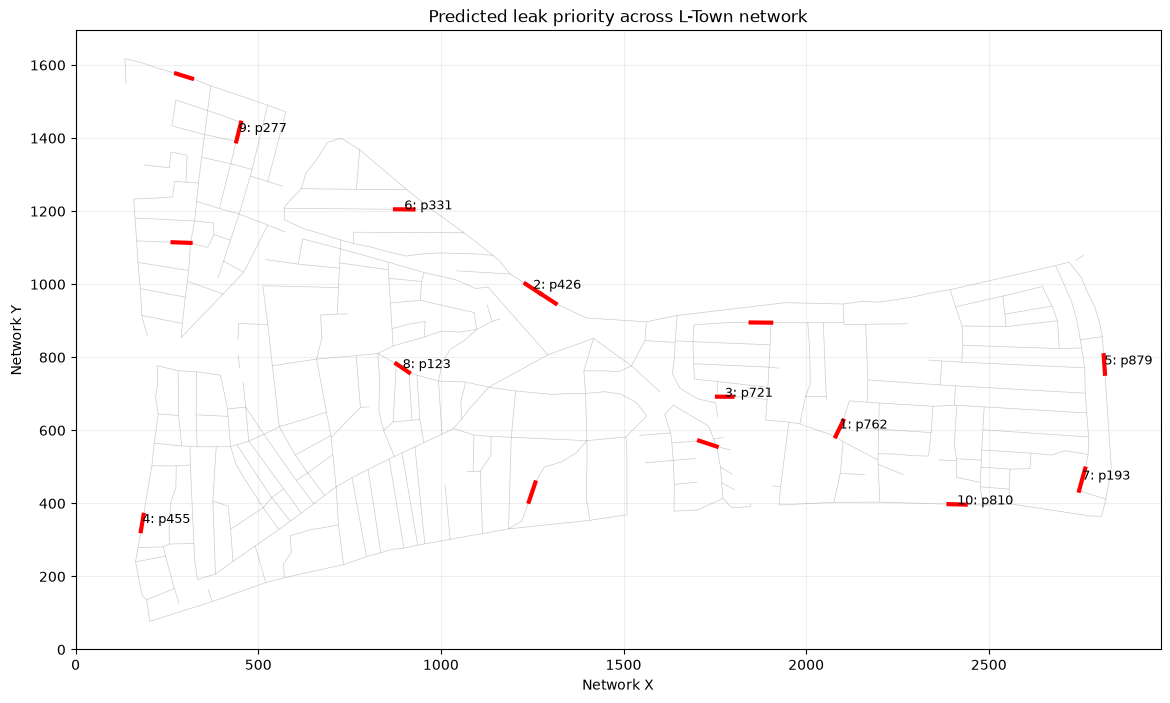

In [10]:
# Candidate table: predictions + pipe nodes + coordinates + midpoint
candidates = current_predictions.merge(all_pipes, left_on="Leak_Location", right_on="Pipe", how="left")
candidates["Mid_X"] = (candidates["Start_X"] + candidates["End_X"]) / 2
candidates["Mid_Y"] = (candidates["Start_Y"] + candidates["End_Y"]) / 2

print(candidates[["Priority_Rank", "Leak_Location", "Start_Node", "End_Node", "Mid_X", "Mid_Y",
                  "Selected_Model", "Predicted_Current_Leakage"]].to_string(index=False))

# ---- map ----
segments = all_pipes[["Start_X", "Start_Y", "End_X", "End_Y"]].dropna().to_numpy()
segments = segments.reshape(-1, 2, 2) if len(segments) else segments
active = candidates[candidates["Predicted_Current_Leakage"] > 0].dropna(subset=["Mid_X"])

fig, ax = plt.subplots(figsize=(14, 10))
ax.add_collection(LineCollection(segments, linewidths=0.5, alpha=0.4, colors="gray"))
for _, p in active.iterrows():
    ax.plot([p["Start_X"], p["End_X"]], [p["Start_Y"], p["End_Y"]], color="red", linewidth=3)
for _, p in active.head(10).iterrows():
    ax.text(p["Mid_X"], p["Mid_Y"], f'{int(p["Priority_Rank"])}: {p["Leak_Location"]}', fontsize=9)
ax.autoscale()
ax.set_aspect("equal")
ax.set_title("Predicted leak priority across L-Town network")
ax.set_xlabel("Network X"); ax.set_ylabel("Network Y"); ax.grid(alpha=0.2)
plt.show()

## 7. Water-loss impact, repair cost and recommendation

Conversion: `ML/day = leak [m3/h] x 24 / 1000`  (the old notebook used `L/s x 86400`, which is 3.6x larger — check `LEAK_TO_M3_PER_H` in the config).

In [11]:
decision = candidates[["Leak_Location", "Start_Node", "End_Node", "Selected_Model", "Predicted_Current_Leakage"]].copy()

decision["Predicted_Loss_m3_per_day"] = decision["Predicted_Current_Leakage"] * LEAK_TO_M3_PER_H * 24
decision["Predicted_Loss_ML_per_day"] = decision["Predicted_Loss_m3_per_day"] / 1000
decision["Recoverable_ML_per_day"] = decision["Predicted_Loss_ML_per_day"] * RECOVERY_FACTOR

decision["Repair_Cost_INR"] = decision["Leak_Location"].map(SCENARIO_COSTS)        # NaN if no scenario cost
decision["Recoverable_ML_per_1Lakh"] = decision["Recoverable_ML_per_day"] / (decision["Repair_Cost_INR"] / 1_00_000)

decision["Water_Loss_Rank"] = decision["Predicted_Loss_ML_per_day"].rank(ascending=False, method="min")
decision["Cost_Effectiveness_Rank"] = decision["Recoverable_ML_per_1Lakh"].rank(ascending=False, method="min")

loss = decision["Predicted_Loss_ML_per_day"]
decision["Recommendation"] = "No current predicted loss"
decision.loc[loss > 0, "Recommendation"] = "Investigate"
decision.loc[(loss >= HIGH_ML_DAY) & (loss < CRITICAL_ML_DAY), "Recommendation"] = "High Water Loss"
decision.loc[loss >= CRITICAL_ML_DAY, "Recommendation"] = "Critical Water Loss"
decision.loc[(decision["Cost_Effectiveness_Rank"] <= 5) & (loss < HIGH_ML_DAY) & (loss > 0), "Recommendation"] = "Cost Efficient"

decision = decision.sort_values("Water_Loss_Rank").reset_index(drop=True)

fmt = {
    "Predicted_Loss_ML_per_day": "{:.3f}".format,
    "Recoverable_ML_per_day": "{:.3f}".format,
    "Repair_Cost_INR": lambda x: f"Rs {x:,.0f}" if pd.notna(x) else "N/A",
    "Recoverable_ML_per_1Lakh": lambda x: f"{x:.3f}" if pd.notna(x) else "N/A",
}
print(decision[["Water_Loss_Rank", "Cost_Effectiveness_Rank", "Leak_Location", "Start_Node", "End_Node",
                "Predicted_Loss_ML_per_day", "Recoverable_ML_per_day", "Repair_Cost_INR",
                "Recoverable_ML_per_1Lakh", "Recommendation"]].to_string(index=False, formatters=fmt))

 Water_Loss_Rank  Cost_Effectiveness_Rank Leak_Location Start_Node End_Node Predicted_Loss_ML_per_day Recoverable_ML_per_day Repair_Cost_INR Recoverable_ML_per_1Lakh            Recommendation
             1.0                     12.0          p762       n683     n264                     0.373                  0.298    Rs 1,000,000                    0.030       Critical Water Loss
             2.0                      6.0          p426       n461     n462                     0.318                  0.254      Rs 500,000                    0.051       Critical Water Loss
             3.0                     14.0          p721       n655     n656                     0.311                  0.249    Rs 1,000,000                    0.025       Critical Water Loss
             4.0                      1.0          p455       n480     n481                     0.263                  0.210      Rs 200,000                    0.105           High Water Loss
             5.0                      9.

## 8. Group active leaks into network regions

In [12]:
G = nx.Graph()
for _, p in all_pipes.iterrows():
    G.add_edge(p["Start_Node"], p["End_Node"], pipe_id=p["Pipe"])
print("Graph nodes:", G.number_of_nodes(), "| edges:", G.number_of_edges())

active_candidates = decision[decision["Predicted_Loss_ML_per_day"] > 0].copy()
cand_pipes = active_candidates["Leak_Location"].tolist()
ends = all_pipes.set_index("Pipe")[["Start_Node", "End_Node"]]

def pipe_distance(a, b):
    """Fewest pipes between two pipes (best of the 4 endpoint pairs); None if not connected."""
    best = None
    for na in ends.loc[a]:
        for nb in ends.loc[b]:
            try:
                d = nx.shortest_path_length(G, na, nb)
            except (nx.NetworkXNoPath, nx.NodeNotFound):
                continue
            best = d if best is None else min(best, d)
    return best

pairs = []
for i, a in enumerate(cand_pipes):
    for b in cand_pipes[i + 1:]:
        pairs.append((a, b, pipe_distance(a, b)))

network_distances = pd.DataFrame(pairs, columns=["Pipe_A", "Pipe_B", "Network_Distance"])
print(network_distances.sort_values("Network_Distance").head(15).to_string(index=False))

# ---- clustering ----
if len(cand_pipes) >= 2:
    finite = network_distances["Network_Distance"].dropna()
    unreachable = (finite.max() + 1) if len(finite) else 1      # unconnected pairs = "farther than anything"
    dm = pd.DataFrame(0.0, index=cand_pipes, columns=cand_pipes)
    for _, r in network_distances.iterrows():
        d = r["Network_Distance"] if pd.notna(r["Network_Distance"]) else unreachable
        dm.loc[r["Pipe_A"], r["Pipe_B"]] = d
        dm.loc[r["Pipe_B"], r["Pipe_A"]] = d

    Z = linkage(squareform(dm.values, checks=False), method="average")
    labels = fcluster(Z, t=min(N_REGIONS, len(cand_pipes)), criterion="maxclust")
else:
    labels = np.ones(len(cand_pipes), dtype=int)

candidate_regions = (
    pd.DataFrame({"Leak_Location": cand_pipes, "Network_Region": labels})
    .merge(active_candidates[["Leak_Location", "Predicted_Loss_ML_per_day", "Recoverable_ML_per_day"]], on="Leak_Location")
    .sort_values(["Network_Region", "Predicted_Loss_ML_per_day"], ascending=[True, False])
    .reset_index(drop=True)
)

region_summary = (
    candidate_regions.groupby("Network_Region")
    .agg(Candidate_Pipes=("Leak_Location", "count"),
         Total_Estimated_Loss_ML_per_day=("Predicted_Loss_ML_per_day", "sum"),
         Potential_Recovery_ML_per_day=("Recoverable_ML_per_day", "sum"),
         Highest_Loss_Pipe=("Leak_Location", "first"))      # rows are already sorted by loss, descending
    .reset_index()
    .sort_values("Total_Estimated_Loss_ML_per_day", ascending=False)
    .reset_index(drop=True)
)
region_summary["Region_Priority"] = region_summary.index + 1

print("\nREGION-LEVEL IMPACT")
print(region_summary[["Region_Priority", "Network_Region", "Candidate_Pipes", "Total_Estimated_Loss_ML_per_day",
                      "Potential_Recovery_ML_per_day", "Highest_Loss_Pipe"]]
      .to_string(index=False, formatters={"Total_Estimated_Loss_ML_per_day": "{:.3f}".format,
                                          "Potential_Recovery_ML_per_day": "{:.3f}".format}))

Graph nodes: 785 | edges: 905
Pipe_A Pipe_B  Network_Distance
  p426   p427               0.0
  p277   p257               4.0
  p721   p710               6.0
  p762   p721               7.0
  p277   p280               7.0
  p426   p331               8.0
  p257   p280               8.0
  p879   p193               9.0
  p762   p710               9.0
  p331   p427               9.0
  p762   p810              10.0
  p193   p810              11.0
  p710   p427              13.0
  p721   p427              13.0
  p426   p721              14.0

REGION-LEVEL IMPACT
 Region_Priority  Network_Region  Candidate_Pipes Total_Estimated_Loss_ML_per_day Potential_Recovery_ML_per_day Highest_Loss_Pipe
               1               1               11                           2.522                         2.018              p762
               2               3                3                           0.462                         0.370              p277
               3               2               

## 9. Final priority tables

In [13]:
final_priority = candidate_regions.merge(
    decision[["Leak_Location", "Start_Node", "End_Node", "Repair_Cost_INR", "Recoverable_ML_per_1Lakh", "Recommendation"]],
    on="Leak_Location", how="left",
)
final_priority["Region_Priority"] = final_priority["Network_Region"].map(
    region_summary.set_index("Network_Region")["Region_Priority"]
)
final_priority["Pipe_Priority_Within_Region"] = (
    final_priority.groupby("Network_Region")["Predicted_Loss_ML_per_day"]
    .rank(ascending=False, method="first").astype(int)
)
final_priority = (
    final_priority.sort_values(["Region_Priority", "Pipe_Priority_Within_Region"])
    .reset_index(drop=True)[[
        "Region_Priority", "Network_Region", "Pipe_Priority_Within_Region", "Leak_Location",
        "Start_Node", "End_Node", "Predicted_Loss_ML_per_day", "Recoverable_ML_per_day",
        "Repair_Cost_INR", "Recoverable_ML_per_1Lakh", "Recommendation",
    ]]
)

candidate_map = final_priority.merge(
    all_pipes[["Pipe", "Start_X", "Start_Y", "End_X", "End_Y"]],
    left_on="Leak_Location", right_on="Pipe", how="left",
)

print(final_priority.to_string(index=False, formatters={
    "Predicted_Loss_ML_per_day": "{:.3f}".format,
    "Recoverable_ML_per_day": "{:.3f}".format,
    "Recoverable_ML_per_1Lakh": lambda x: f"{x:.3f}" if pd.notna(x) else "N/A",
}))

print("\nfinal_priority:", final_priority.shape, "| all_pipes:", all_pipes.shape, "| candidate_map:", candidate_map.shape)

 Region_Priority  Network_Region  Pipe_Priority_Within_Region Leak_Location Start_Node End_Node Predicted_Loss_ML_per_day Recoverable_ML_per_day  Repair_Cost_INR Recoverable_ML_per_1Lakh      Recommendation
               1               1                            1          p762       n683     n264                     0.373                  0.298        1000000.0                    0.030 Critical Water Loss
               1               1                            2          p426       n461     n462                     0.318                  0.254         500000.0                    0.051 Critical Water Loss
               1               1                            3          p721       n655     n656                     0.311                  0.249        1000000.0                    0.025 Critical Water Loss
               1               1                            4          p879       n765     n766                     0.262                  0.210         500000.0           

## 10. Export

In [14]:
OUT_DIR.mkdir(parents=True, exist_ok=True)

outputs = {
    "final_intervention_priorities": final_priority,
    "network_topology": all_pipes,
    "candidate_pipe_locations": candidate_map,
}
for name, df in outputs.items():
    df.to_csv(OUT_DIR / f"{name}.csv", index=False)
    df.to_json(OUT_DIR / f"{name}.json", orient="records", indent=2)

print("Exported to", OUT_DIR.resolve())
for name in outputs:
    print(f"  {name}.csv / .json")

Exported to /Users/sriramdarla/Downloads/WeMakeDevs-main/data
  final_intervention_priorities.csv / .json
  network_topology.csv / .json
  candidate_pipe_locations.csv / .json
